In [7]:
%pip install -q gdown

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
import os
import numpy as np
from pathlib import Path
from PIL import Image
from tqdm import tqdm

In [8]:
import os
import gdown

FILE_ID = "1nmAPGD8EOjVIS1BZ3fiVHNZDw5Q4HiIl"
ZIP_PATH = r"D:\data\pneumonia_dataset.zip"   # path pendek, di luar repo Git

os.makedirs(os.path.dirname(ZIP_PATH), exist_ok=True)
gdown.download(id=FILE_ID, output=ZIP_PATH, quiet=False)

c:\Users\grace\AppData\Local\Programs\Python\Python311\Lib\http\cookiejar.py:2080: UserWarning: http.cookiejar bug!
Traceback (most recent call last):
  File "c:\Users\grace\AppData\Local\Programs\Python\Python311\Lib\http\cookiejar.py", line 2041, in _really_load
    domain, domain_specified, path, secure, expires, name, value = \
    ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
ValueError: not enough values to unpack (expected 7, got 1)

  _warn_unhandled_exception()
c:\Users\grace\AppData\Local\Programs\Python\Python311\Lib\site-packages\gdown\download.py:235: UserWarning: Failed to load cookies from C:\Users\grace\.cache/gdown/cookies.txt: invalid Netscape format cookies file 'C:\\Users\\grace\\.cache/gdown/cookies.txt': 'mpq3dm4fdv2i005891nusndluvtq8o46'
  sess, cookies_file = _get_session(
Downloading...
From (original): https://drive.google.com/uc?id=1nmAPGD8EOjVIS1BZ3fiVHNZDw5Q4HiIl
From (redirected): https://drive.google.com/uc?id=1nmAPGD8EOjVIS1BZ3fiVHNZDw5Q4H

'D:\\data\\pneumonia_dataset.zip'

In [9]:
import os
import zipfile
import shutil

ZIP_PATH = r"D:\data\pneumonia_dataset.zip"
OUTPUT_DIR = r"D:\uni - 5th sem\lecture\Capstone-TeleradiologiAI\Pneumonia\dataset"

# Prefix \\?\ supaya Windows mengabaikan batas 260 karakter
def long_path(p):
    p = os.path.abspath(p)
    return p if p.startswith("\\\\?\\") else "\\\\?\\" + p

os.makedirs(long_path(OUTPUT_DIR), exist_ok=True)

with zipfile.ZipFile(ZIP_PATH) as zf:
    members = zf.infolist()
    for i, m in enumerate(members, 1):
        target = os.path.join(OUTPUT_DIR, *m.filename.split("/"))
        if m.is_dir():
            os.makedirs(long_path(target), exist_ok=True)
            continue
        os.makedirs(long_path(os.path.dirname(target)), exist_ok=True)
        with zf.open(m) as src, open(long_path(target), "wb") as dst:
            shutil.copyfileobj(src, dst)
        if i % 500 == 0:
            print(f"{i}/{len(members)} file diekstrak")

print("Selesai ->", OUTPUT_DIR)

500/17591 file diekstrak
1000/17591 file diekstrak
1500/17591 file diekstrak
2000/17591 file diekstrak
2500/17591 file diekstrak
3000/17591 file diekstrak
3500/17591 file diekstrak
4000/17591 file diekstrak
4500/17591 file diekstrak
5000/17591 file diekstrak
5500/17591 file diekstrak
6000/17591 file diekstrak
6500/17591 file diekstrak
7000/17591 file diekstrak
7500/17591 file diekstrak
8000/17591 file diekstrak
8500/17591 file diekstrak
9000/17591 file diekstrak
9500/17591 file diekstrak
10000/17591 file diekstrak
10500/17591 file diekstrak
11000/17591 file diekstrak
11500/17591 file diekstrak
12000/17591 file diekstrak
12500/17591 file diekstrak
13000/17591 file diekstrak
13500/17591 file diekstrak
14000/17591 file diekstrak
14500/17591 file diekstrak
15000/17591 file diekstrak
15500/17591 file diekstrak
16000/17591 file diekstrak
16500/17591 file diekstrak
17000/17591 file diekstrak
17500/17591 file diekstrak
Selesai -> D:\uni - 5th sem\lecture\Capstone-TeleradiologiAI\Pneumonia\data

# X. Check the Dataset

In [13]:
import os
from pathlib import Path

def find_repo_root(marker="Capstone-TeleradiologiAI"):
    p = Path.cwd().resolve()
    for parent in [p, *p.parents]:
        if parent.name == marker or (parent / ".git").exists():
            return parent
    raise FileNotFoundError(f"Folder repo '{marker}' tidak ditemukan dari {p}")

ROOT = find_repo_root()
TRAIN_DIR = ROOT / "Pneumonia" / "dataset" / "chest_xray" / "train"
EXT = (".jpg", ".jpeg", ".png")

def long_path(p):
    p = os.path.abspath(p)
    return p if p.startswith("\\\\?\\") else "\\\\?\\" + p

def count_images(folder):
    return sum(1 for f in os.listdir(long_path(folder)) if f.lower().endswith(EXT))

print("Root repo:", ROOT)

total = 0
for kelas in ["NORMAL", "PNEUMONIA"]:
    jumlah = count_images(TRAIN_DIR / kelas)
    total += jumlah
    print(f"{kelas:<10}: {jumlah} foto")

print(f"{'TOTAL':<10}: {total} foto")

Root repo: D:\uni - 5th sem\lecture\Capstone-TeleradiologiAI
NORMAL    : 1341 foto
PNEUMONIA : 3875 foto
TOTAL     : 5216 foto


In [14]:
import os
from pathlib import Path

def find_repo_root(marker="Capstone-TeleradiologiAI"):
    p = Path.cwd().resolve()
    for parent in [p, *p.parents]:
        if parent.name == marker or (parent / ".git").exists():
            return parent
    raise FileNotFoundError(f"Folder repo '{marker}' tidak ditemukan dari {p}")

ROOT = find_repo_root()
TEST_DIR = ROOT / "Pneumonia" / "dataset" / "chest_xray" / "test"
EXT = (".jpg", ".jpeg", ".png")

def long_path(p):
    p = os.path.abspath(p)
    return p if p.startswith("\\\\?\\") else "\\\\?\\" + p

def count_images(folder):
    return sum(1 for f in os.listdir(long_path(folder)) if f.lower().endswith(EXT))

print("Root repo:", ROOT)

total = 0
for kelas in ["NORMAL", "PNEUMONIA"]:
    jumlah = count_images(TEST_DIR / kelas)
    total += jumlah
    print(f"{kelas:<10}: {jumlah} foto")

print(f"{'TOTAL':<10}: {total} foto")

Root repo: D:\uni - 5th sem\lecture\Capstone-TeleradiologiAI
NORMAL    : 234 foto
PNEUMONIA : 390 foto
TOTAL     : 624 foto


# 1. Read Dataset

In [21]:
# ROOT dari find_repo_root() di kode sebelumnya
DATASET_DIR = ROOT / "Pneumonia" / "dataset" / "chest_xray"
TRAIN_DIR = DATASET_DIR / "train"
TEST_DIR  = DATASET_DIR / "test"

IMG_SIZE = (224, 224)
EXT = (".jpg", ".jpeg", ".png")
CLASSES = ["NORMAL", "PNEUMONIA"]          # NORMAL = 0, PNEUMONIA = 1

def long_path(p):
    p = os.path.abspath(p)
    return p if p.startswith("\\\\?\\") else "\\\\?\\" + p

def load_images(data_dir, img_size=IMG_SIZE, mode="RGB"):
    """Baca semua gambar di data_dir/<kelas>. mode: 'RGB' atau 'L' (grayscale)."""
    data_dir = Path(data_dir)
    X, y, paths = [], [], []
    for label, kelas in enumerate(CLASSES):
        folder = data_dir / kelas
        files = sorted(f for f in os.listdir(long_path(folder)) if f.lower().endswith(EXT))
        for fname in tqdm(files, desc=f"{data_dir.name}/{kelas}"):
            fpath = folder / fname
            with Image.open(long_path(fpath)) as img:
                img = img.convert(mode).resize(img_size)
                X.append(np.asarray(img, dtype=np.uint8))
            y.append(label)
            paths.append(str(fpath))
    return np.array(X), np.array(y), paths

# Train dan test dibaca sendiri-sendiri
X_train, label_train, train_paths = load_images(TRAIN_DIR)
X_test,  label_test,  test_paths  = load_images(TEST_DIR)


print("X_train:", X_train.shape, "| y_train:", label_train.shape)
print("X_test :", X_test.shape,  "| y_test :", label_test.shape)

test/PNEUMONIA: 100%|██████████| 390/390 [00:04<00:00, 97.16it/s] 


X_train: (5216, 224, 224, 3) | y_train: (5216,)
X_test : (624, 224, 224, 3) | y_test : (624,)


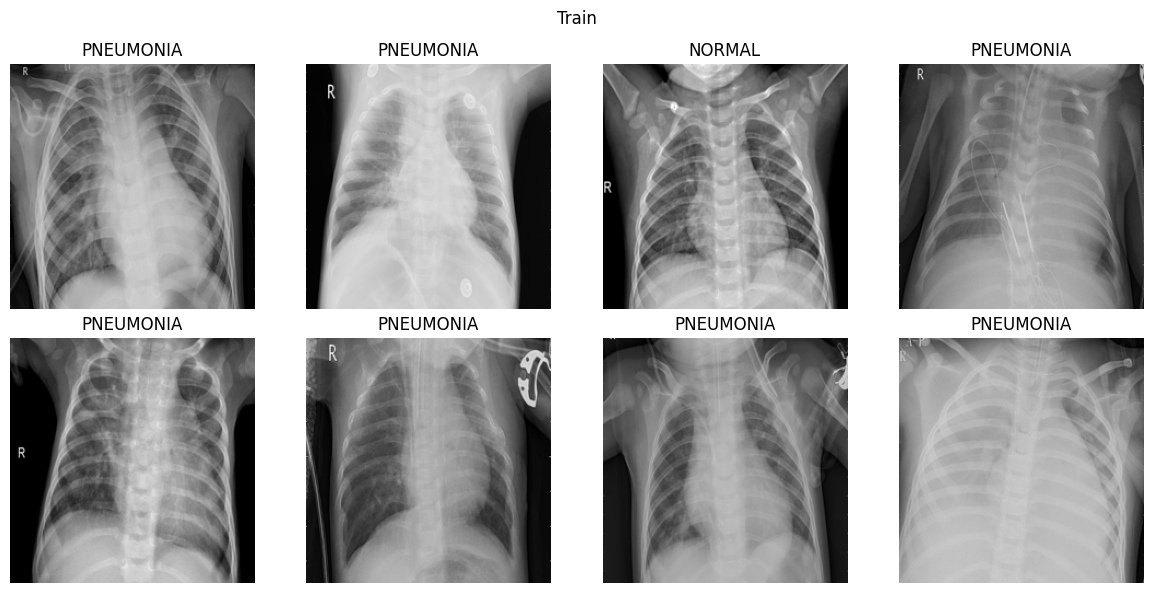

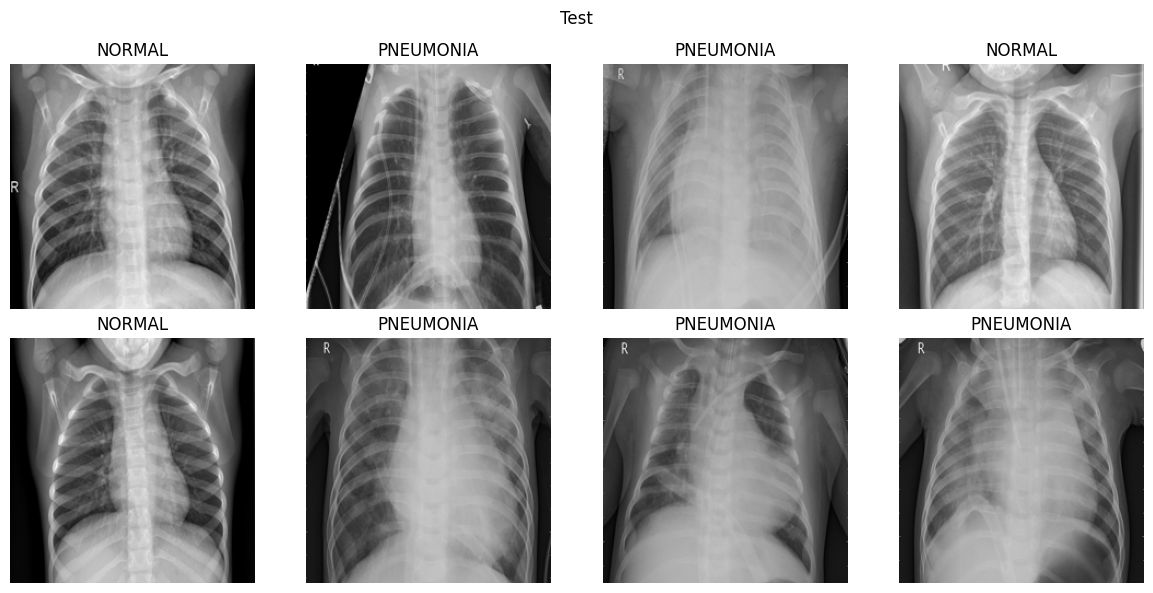

In [19]:
import matplotlib.pyplot as plt

def show_samples(X, y, title, n=8):
    fig, axes = plt.subplots(2, n // 2, figsize=(12, 6))
    fig.suptitle(title)
    for ax in axes.flat:
        i = np.random.randint(len(X))
        ax.imshow(X[i])
        ax.set_title(CLASSES[y[i]])
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_samples(X_train, y_train, "Train")
show_samples(X_test, y_test, "Test")

# 2. Modeling

In [22]:
#configuration

import copy
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

SEED = 42
BATCH_SIZE = 32
EPOCHS = 15
LR = 1e-3
PATIENCE = 4                     
SAVE_PATH = ROOT / "Pneumonia" / "densenet121_best.pth"

torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


In [23]:
#split data
X_tr, X_val, label_tr, label_val = train_test_split(
    X_train, label_train, test_size=0.2, stratify=label_train, random_state=SEED
)

In [24]:
class XrayDataset(Dataset):
    def __init__(self, X, y):
        self.X, self.y = X, y
        self.norm = transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                         std=[0.229, 0.224, 0.225])

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        img = torch.from_numpy(self.X[i]).permute(2, 0, 1).float() / 255.0   # HWC -> CHW, 0-1
        return self.norm(img), int(self.y[i])

train_loader = DataLoader(XrayDataset(X_tr, label_tr),   batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(XrayDataset(X_val, label_val), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(XrayDataset(X_test, label_test), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

# Class weight untuk data tidak seimbang
counts = np.bincount(label_tr)
class_weights = torch.tensor(len(label_tr) / (len(counts) * counts), dtype=torch.float32)
print("Train:", len(label_tr), "| Val:", len(label_val), "| Test:", len(label_test))
print("Class weights:", dict(zip(CLASSES, class_weights.numpy().round(3))))

Train: 4172 | Val: 1044 | Test: 624
Class weights: {'NORMAL': np.float32(1.944), 'PNEUMONIA': np.float32(0.673)}


In [25]:
def build_model(num_classes=2):
    model = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)

    # Bekukan seluruh backbone pretrained
    for p in model.parameters():
        p.requires_grad = False

    # Classifier baru (otomatis trainable)
    model.classifier = nn.Linear(model.classifier.in_features, num_classes)
    return model

def set_train_mode(model):
    """Backbone tetap eval supaya BatchNorm tidak ikut berubah."""
    model.train()
    model.features.eval()

model = build_model().to(device)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"Trainable: {trainable:,} / {total:,}")

criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))
optimizer = optim.Adam(model.classifier.parameters(), lr=LR)

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to C:\Users\grace/.cache\torch\hub\checkpoints\densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [01:01<00:00, 527kB/s] 


Trainable: 2,050 / 6,955,906


In [ ]:
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

best_val_loss = float("inf")
best_state = None
wait = 0

for epoch in range(1, EPOCHS + 1):

    # ==================== TRAINING ====================
    model.train()
    model.features.eval()       # backbone tetap eval (BatchNorm tidak berubah)

    train_loss_total = 0.0
    train_correct = 0
    train_n = 0

    train_bar = tqdm(train_loader, desc=f"Epoch {epoch:02d}/{EPOCHS} [train]", leave=False)

    for images, labels in train_bar:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss_total += loss.item() * images.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_n += images.size(0)

        # Tampilkan loss dan akurasi berjalan di samping progress bar
        train_bar.set_postfix(loss=f"{train_loss_total / train_n:.4f}",
                              acc=f"{train_correct / train_n:.4f}")

    train_loss = train_loss_total / train_n
    train_acc = train_correct / train_n

    # ==================== VALIDASI ====================
    model.eval()

    val_loss_total = 0.0
    val_correct = 0
    val_n = 0

    val_bar = tqdm(val_loader, desc=f"Epoch {epoch:02d}/{EPOCHS} [val]  ", leave=False)

    with torch.no_grad():
        for images, labels in val_bar:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_total += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_n += images.size(0)

            val_bar.set_postfix(loss=f"{val_loss_total / val_n:.4f}",
                                acc=f"{val_correct / val_n:.4f}")

    val_loss = val_loss_total / val_n
    val_acc = val_correct / val_n

    # ==================== CATAT & TAMPILKAN ====================
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(f"Epoch {epoch:02d}/{EPOCHS} | "
          f"train loss {train_loss:.4f} acc {train_acc:.4f} | "
          f"val loss {val_loss:.4f} acc {val_acc:.4f}")

    # ==================== SIMPAN MODEL TERBAIK ====================
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        torch.save(best_state, SAVE_PATH)
        wait = 0
        print("  -> model terbaik disimpan")
    else:
        wait += 1
        print(f"  -> tidak membaik ({wait}/{PATIENCE})")
        if wait >= PATIENCE:
            print(f"Early stopping di epoch {epoch}")
            break

model.load_state_dict(best_state)
print("Model terbaik dimuat. Val loss:", round(best_val_loss, 4))

KeyboardInterrupt: 